In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [18]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 2. LOAD DATASET
# ==========================================

df = pd.read_csv("/kaggle/input/datasets/johnsmith88/heart-disease-dataset/heart.csv")

In [10]:
# ==========================================
# 3. EXPLORE DATASET
# ==========================================

print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nTarget Distribution:")
target = "target"
print(df[target].value_counts())

print("\nStatistical Description:")
display(df.describe(include="all"))

Dataset Shape:
(1025, 14)

First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal     

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [11]:
# ==========================================
# DATA CLEANING
# ==========================================

# Create a copy
data = df.copy()

# Check data types
print("Data Types:")
print(data.dtypes)

# Check categorical values
categorical_cols = data.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(data[col].unique())

# Check numerical columns
numerical_cols = data.select_dtypes(include=np.number).columns

print("\nNumerical Columns:")
print(numerical_cols.tolist())

# Check target distribution
print("\nTarget Distribution:")
print(data['target'].value_counts(normalize=True) * 100)

# Final check
print("\nDataset Shape:", data.shape)
print("Missing Values:", data.isnull().sum().sum())
print("Duplicates:", data.duplicated().sum())

Data Types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object

Numerical Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Target Distribution:
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64

Dataset Shape: (1025, 14)
Missing Values: 0
Duplicates: 723


In [12]:
# ==========================================
# DATA PREPROCESSING
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Separate Features and Target
X = data.drop(columns=['target'])
y = data['target']

# Convert Categorical Features using One-Hot Encoding
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Feature Scaling
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Display Results
print("Original Features:", X.shape[1])

print("\nTraining Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nScaled Training Shape:", X_train_s.shape)
print("Scaled Testing Shape:", X_test_s.shape)

print("\nTarget Distribution in Training:")
print(y_train.value_counts())

Original Features: 13

Training Shape: (820, 13)
Testing Shape: (205, 13)

Scaled Training Shape: (820, 13)
Scaled Testing Shape: (205, 13)

Target Distribution in Training:
target
1    421
0    399
Name: count, dtype: int64


Random Forest Results
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       100
           1       1.00      1.00      1.00       105

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205



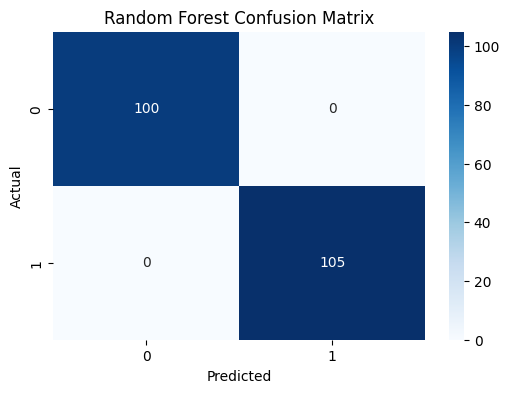

In [19]:
# ==========================================
# RANDOM FOREST CLASSIFIER
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Create Model
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Model
rf.fit(X_train, y_train)

# Predictions
rf_preds = rf.predict(X_test)

# Evaluate Model
print("Random Forest Results")

print("Accuracy:", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(y_test, rf_preds))
print("Recall:", recall_score(y_test, rf_preds))
print("F1 Score:", f1_score(y_test, rf_preds))

print("\nClassification Report:")
print(classification_report(y_test, rf_preds))

# Confusion Matrix
cm = confusion_matrix(y_test, rf_preds)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Neural Network Results (Mini-Batch GD)
Accuracy: 0.8097560975609757
Precision: 0.7619047619047619
Recall: 0.9142857142857143
F1 Score: 0.8311688311688312


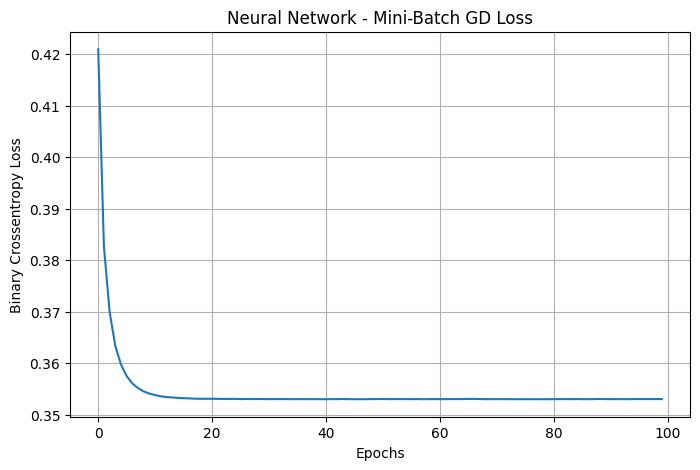

In [20]:
# ==========================================
# NEURAL NETWORK USING MINI-BATCH GD
# ==========================================

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Initialization
np.random.seed(42)

n_features = X_train_s.shape[1]

weights = np.zeros(n_features)
bias = 0.0

learning_rate = 0.1
epochs = 100
batch_size = 32

losses = []

# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# Training using Mini-Batch Gradient Descent
for epoch in range(epochs):

    # Shuffle Training Data
    indices = np.random.permutation(len(X_train_s))

    X_shuffled = X_train_s[indices]
    y_shuffled = np.array(y_train)[indices]

    for i in range(0, len(X_shuffled), batch_size):

        # Select Mini-Batch
        X_batch = X_shuffled[i:i + batch_size]
        y_batch = y_shuffled[i:i + batch_size]

        # Forward Propagation
        linear = np.dot(X_batch, weights) + bias
        predictions = sigmoid(linear)

        # Calculate Gradients
        dw = np.dot(X_batch.T, predictions - y_batch) / len(y_batch)
        db = np.mean(predictions - y_batch)

        # Update Weights
        weights -= learning_rate * dw
        bias -= learning_rate * db

    # Calculate Loss After Each Epoch
    train_linear = np.dot(X_train_s, weights) + bias
    train_probs = sigmoid(train_linear)

    epsilon = 1e-15
    train_probs = np.clip(train_probs, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_train * np.log(train_probs) +
        (1 - y_train) * np.log(1 - train_probs)
    )

    losses.append(loss)

# ==========================================
# PREDICTIONS
# ==========================================

nn_probs = sigmoid(np.dot(X_test_s, weights) + bias)

nn_preds = (nn_probs >= 0.5).astype(int)

# ==========================================
# EVALUATION
# ==========================================

print("Neural Network Results (Mini-Batch GD)")

print("Accuracy:", accuracy_score(y_test, nn_preds))
print("Precision:", precision_score(y_test, nn_preds))
print("Recall:", recall_score(y_test, nn_preds))
print("F1 Score:", f1_score(y_test, nn_preds))

# ==========================================
# LOSS VISUALIZATION
# ==========================================

plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.title("Neural Network - Mini-Batch GD Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Crossentropy Loss")
plt.grid()
plt.show()

In [21]:
# ==========================================
# VOTING ENSEMBLE (RF + MINI-BATCH GD)
# ==========================================

# Random Forest Probabilities
rf_probs = rf.predict_proba(X_test)[:, 1]

# Mini-Batch GD Probabilities
# nn_probs is calculated in Mini-Batch GD code

# Combine Predictions
voting_preds_proba = (rf_probs + nn_probs) / 2

# Final Predictions
voting_preds = (voting_preds_proba >= 0.5).astype(int)

# Evaluation
print("Voting Ensemble Results (RF + Mini-Batch GD)")

print("Accuracy:", accuracy_score(y_test, voting_preds))
print("Precision:", precision_score(y_test, voting_preds))
print("Recall:", recall_score(y_test, voting_preds))
print("F1 Score:", f1_score(y_test, voting_preds))

print("\nClassification Report:")
print(classification_report(y_test, voting_preds))

Voting Ensemble Results (RF + Mini-Batch GD)
Accuracy: 0.9902439024390244
Precision: 0.9813084112149533
Recall: 1.0
F1 Score: 0.9905660377358491

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.98      0.99       100
           1       0.98      1.00      0.99       105

    accuracy                           0.99       205
   macro avg       0.99      0.99      0.99       205
weighted avg       0.99      0.99      0.99       205

